# Customer Churn Prediction – Telco
Business problem → data prep → EDA → models → evaluation → saved pipeline.

## 1. Load & understand data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
df = pd.read_csv('../data/telco_customer_churn.csv')
print(df.shape); display(df.head()); df.info(); display(df.describe())
print('Duplicates:', df.duplicated().sum(), '| duplicate IDs:', df.customerID.duplicated().sum())
print(df.isna().sum().sum(), 'NaN; blank TotalCharges:', (df.TotalCharges.str.strip()=='').sum())
for c in df.select_dtypes(exclude='number'): 
    if df[c].nunique()<8: print(c, df[c].unique().tolist())

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Duplicates: 0 | duplicate IDs: 0
0 NaN; blank TotalCharges: 11
gender ['Female', 'Male']
Partner ['Yes', 'No']
Dependents ['No', 'Yes']
PhoneService ['No', 'Yes']
MultipleLines ['No phone service', 'No', 'Yes']
InternetService ['DSL', 'Fiber optic', 'No']
OnlineSecurity ['No', 'Yes', 'No internet service']
OnlineBackup ['Yes', 'No', 'No internet service']
DeviceProtection ['No', 'Yes', 'No internet service']
TechSupport ['No', 'Yes', 'No internet service']
StreamingTV ['No', 'Yes', 'No internet service']
StreamingMovies ['No', 'Yes', 'No internet service']
Contract ['Month-to-month', 'One year', 'Two year']
PaperlessBilling ['Yes', 'No']
PaymentMethod ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn ['No', 'Yes']


## 2. Cleaning
`TotalCharges` is text with 11 blanks (customers with tenure 0) → convert to numeric (NaN, imputed later in the pipeline to avoid leakage). `customerID` is an identifier → dropped. No leakage columns: all features are known before churn.

In [2]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
print(df[df.TotalCharges.isna()][['tenure','TotalCharges']].head(3)); print(df.TotalCharges.isna().sum())
df['Churn_flag']=(df.Churn=='Yes').astype(int)

     tenure  TotalCharges
488       0           NaN
753       0           NaN
936       0           NaN
11


## 3. EDA

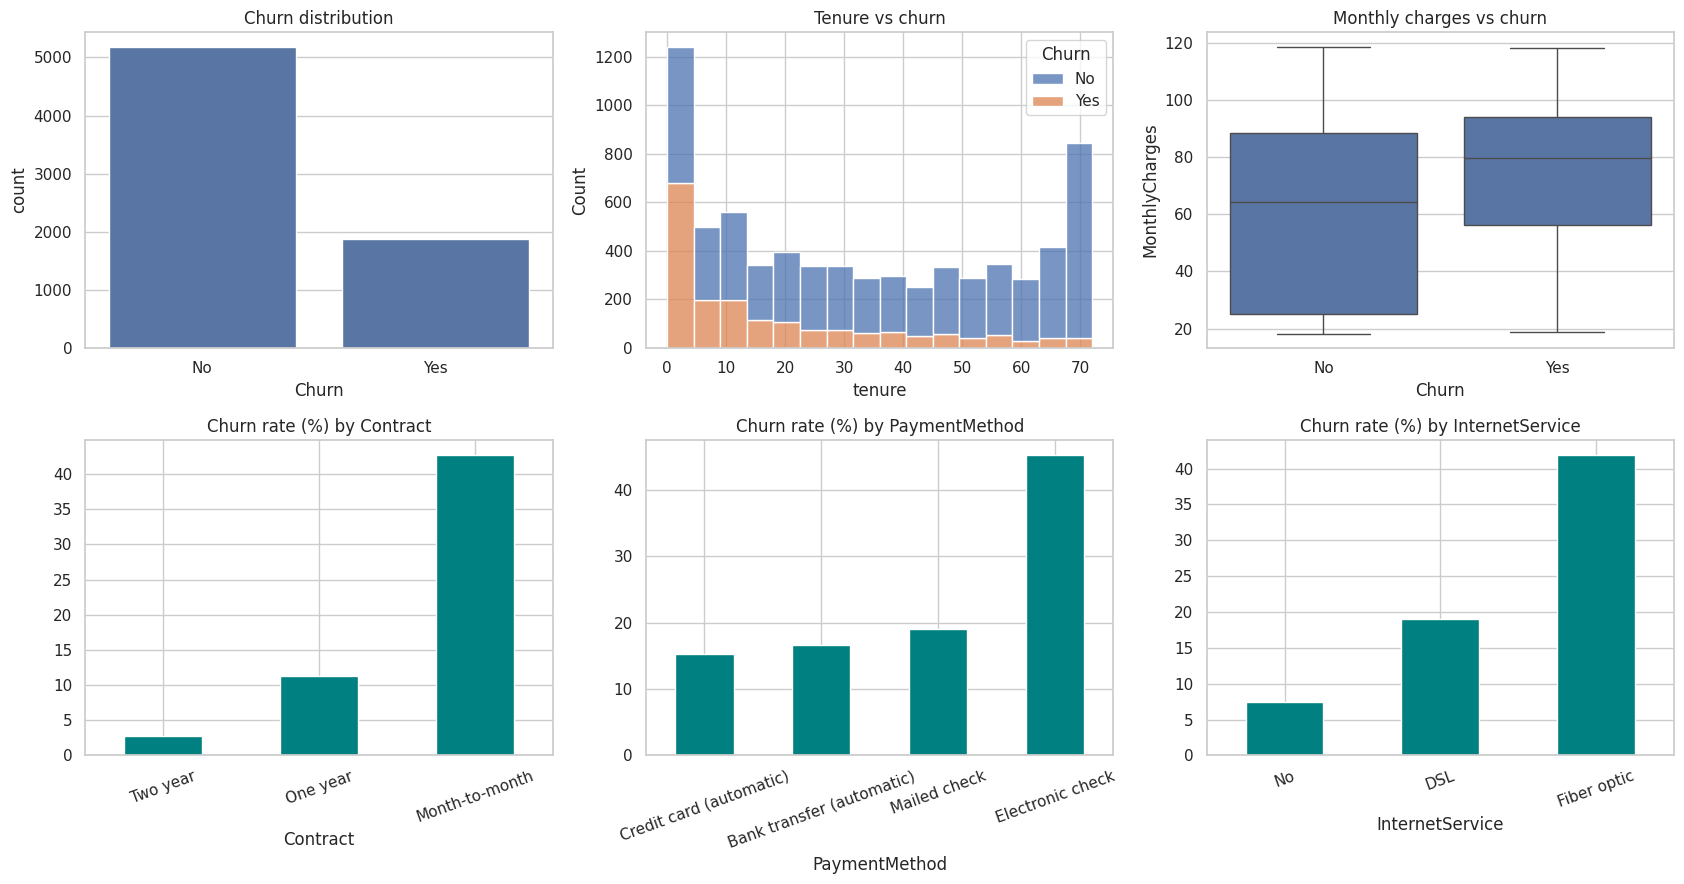

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_flag, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_flag, dtype: float64 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn_flag, dtype: float64 

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn_flag, dtype: float64 

OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: Churn_flag, dtype: float64 



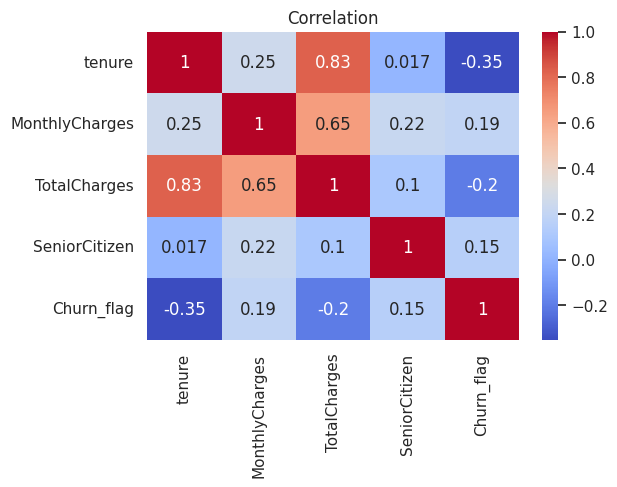

In [3]:
sns.set_theme(style='whitegrid'); fig,ax=plt.subplots(2,3,figsize=(17,9))
sns.countplot(data=df,x='Churn',ax=ax[0,0]); ax[0,0].set_title('Churn distribution')
sns.histplot(data=df,x='tenure',hue='Churn',multiple='stack',ax=ax[0,1]); ax[0,1].set_title('Tenure vs churn')
sns.boxplot(data=df,x='Churn',y='MonthlyCharges',ax=ax[0,2]); ax[0,2].set_title('Monthly charges vs churn')
for a,c in zip([ax[1,0],ax[1,1],ax[1,2]],['Contract','PaymentMethod','InternetService']):
    r=df.groupby(c).Churn_flag.mean().mul(100).sort_values(); r.plot.bar(ax=a,color='teal'); a.set_title(f'Churn rate (%) by {c}'); a.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()
print(df.Churn.value_counts(normalize=True).round(3))
for c in ['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity']: print((df.groupby(c).Churn_flag.mean()*100).round(1),'\n')
plt.figure(figsize=(6,4)); sns.heatmap(df[['tenure','MonthlyCharges','TotalCharges','SeniorCitizen','Churn_flag']].corr(),annot=True,cmap='coolwarm'); plt.title('Correlation'); plt.show()

## 4. Modelling & evaluation (preprocessing fitted inside Pipeline → no leakage)

In [4]:
import pandas as pd, numpy as np, json, joblib, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

df = pd.read_csv("../data/telco_customer_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # 11 blank strings -> NaN (new customers, tenure=0)
df = df.drop(columns="customerID")                                         # identifier, no predictive value
y = (df.pop("Churn") == "Yes").astype(int)
num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = [c for c in df.columns if c not in num]
X_tr, X_te, y_tr, y_te = train_test_split(df, y, test_size=0.2, stratify=y, random_state=42)

def prep(scale=True):
    n = Pipeline([("imp", __import__("sklearn.impute", fromlist=["x"]).SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else []))
    return ColumnTransformer([("num", n, num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

models = {
 "Logistic Regression": Pipeline([("prep", prep()), ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
 "Decision Tree": Pipeline([("prep", prep(False)), ("m", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))]),
 "Random Forest": Pipeline([("prep", prep(False)), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1))]),
 "KNN": Pipeline([("prep", prep()), ("m", KNeighborsClassifier(n_neighbors=15))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
res = {}
for k, p in models.items():
    cvf = cross_val_score(p, X_tr, y_tr, cv=cv, scoring="f1").mean()
    p.fit(X_tr, y_tr); pr = p.predict(X_te); pb = p.predict_proba(X_te)[:, 1]
    res[k] = dict(accuracy=accuracy_score(y_te, pr), precision=precision_score(y_te, pr), recall=recall_score(y_te, pr),
                  f1=f1_score(y_te, pr), roc_auc=roc_auc_score(y_te, pb), cv_f1=cvf, confusion_matrix=confusion_matrix(y_te, pr).tolist())
    print(k, {a: round(b, 3) for a, b in res[k].items() if a != "confusion_matrix"})

# tune logistic regression (best recall/AUC balance expected)
gs = GridSearchCV(models["Logistic Regression"], {"m__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="f1").fit(X_tr, y_tr)
print("best LR params", gs.best_params_)
best = gs.best_estimator_
pr = best.predict(X_te); pb = best.predict_proba(X_te)[:, 1]
res["Logistic Regression (tuned)"] = dict(accuracy=accuracy_score(y_te, pr), precision=precision_score(y_te, pr), recall=recall_score(y_te, pr),
    f1=f1_score(y_te, pr), roc_auc=roc_auc_score(y_te, pb), cv_f1=gs.best_score_, confusion_matrix=confusion_matrix(y_te, pr).tolist())
print("tuned", {a: round(b, 3) for a, b in res["Logistic Regression (tuned)"].items() if a != "confusion_matrix"})

# select final model by F1 (recall-weighted business need) among all
final_name = max(res, key=lambda k: res[k]["f1"])
final = best if "tuned" in final_name else models[final_name]
print("FINAL:", final_name)
joblib.dump(final, "../models/churn_pipeline.pkl")
# consistency test
l = joblib.load("../models/churn_pipeline.pkl"); assert np.allclose(l.predict_proba(X_te), final.predict_proba(X_te))
# feature importance / coefficients
names = final.named_steps["prep"].get_feature_names_out()
m = final.named_steps["m"]
imp = m.coef_[0] if hasattr(m, "coef_") else m.feature_importances_
fi = sorted(zip([n.split("__")[1] for n in names], map(float, imp)), key=lambda t: -abs(t[1]))[:15]
json.dump(dict(final=final_name, results=res, importance=fi, n_train=len(X_tr), n_test=len(X_te),
               train_churn=float(y_tr.mean()), test_churn=float(y_te.mean())), open("../models/metrics.json", "w"), indent=1)


Logistic Regression {'accuracy': 0.738, 'precision': 0.504, 'recall': 0.783, 'f1': 0.614, 'roc_auc': 0.841, 'cv_f1': np.float64(0.628)}


Decision Tree {'accuracy': 0.755, 'precision': 0.527, 'recall': 0.759, 'f1': 0.622, 'roc_auc': 0.832, 'cv_f1': np.float64(0.615)}


Random Forest {'accuracy': 0.767, 'precision': 0.544, 'recall': 0.738, 'f1': 0.627, 'roc_auc': 0.841, 'cv_f1': np.float64(0.63)}


KNN {'accuracy': 0.778, 'precision': 0.584, 'recall': 0.564, 'f1': 0.574, 'roc_auc': 0.821, 'cv_f1': np.float64(0.578)}


best LR params {'m__C': 0.1}
tuned {'accuracy': 0.742, 'precision': 0.51, 'recall': 0.786, 'f1': 0.618, 'roc_auc': 0.841, 'cv_f1': np.float64(0.629)}
FINAL: Random Forest


## 5. Evaluation summary & saved-model check

,accuracy,precision,recall,f1,roc_auc,cv_f1
Logistic Regression,0.738,0.504,0.783,0.614,0.841,0.628
Decision Tree,0.755,0.527,0.759,0.622,0.832,0.615
Random Forest,0.767,0.544,0.738,0.627,0.841,0.630
KNN,0.778,0.584,0.564,0.574,0.821,0.578
Logistic Regression (tuned),0.742,0.510,0.786,0.618,0.841,0.629


Final model: Random Forest


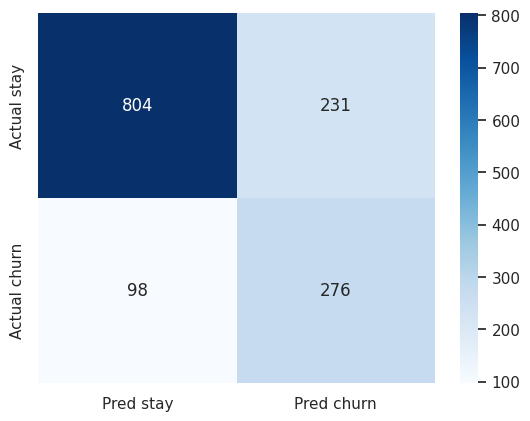

Top features: [['Contract_Month-to-month', 0.12833379740726916], ['tenure', 0.12534552390602932], ['TotalCharges', 0.10278536519409971], ['MonthlyCharges', 0.07509607861640191], ['OnlineSecurity_No', 0.0604060241815566], ['Contract_Two year', 0.05883008618660224], ['InternetService_Fiber optic', 0.04767022938089574], ['TechSupport_No', 0.04654784242232433]]


Reloaded pipeline gives same predictions: True


In [5]:
import json; R=json.load(open('../models/metrics.json')); display(pd.DataFrame(R['results']).T.drop(columns='confusion_matrix').astype(float).round(3))
print('Final model:',R['final'])
cm=np.array(R['results'][R['final']]['confusion_matrix']); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Pred stay','Pred churn'],yticklabels=['Actual stay','Actual churn']); plt.show()
print('Top features:',R['importance'][:8])
loaded=joblib.load('../models/churn_pipeline.pkl'); print('Reloaded pipeline gives same predictions:', (loaded.predict(X_te)==final.predict(X_te)).all())